## 1. Import libraries

In [7]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Common helper functions

In [2]:
def plot_errors(errors, threshold, title):
    plt.figure(figsize=(10, 4))
    plt.plot(errors, label='Reconstruction Error')
    plt.axhline(threshold, color='red', linestyle='--', label='Threshold')
    plt.title(title)
    plt.xlabel('Sample')
    plt.ylabel('Reconstruction Error')
    plt.legend()
    plt.show()


def evaluate_anomalies(true_labels, predicted_labels):
    cm = confusion_matrix(true_labels, predicted_labels)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title("Confusion Matrix")
    plt.show()

    print("Classification Report:")
    print(classification_report(
        true_labels, predicted_labels, zero_division=0
    ))

# 3A. Credit Card Fraud Detection using Autoencoder

**Dataset:** Kaggle Credit Card Fraud Detection (`creditcard.csv`).

The `Class` column is the label: 0 = normal transaction, 1 = fraud. The model is trained only on normal transactions.

## Stage 1: Load and preprocess data

In [3]:
data = pd.read_csv('dataset/AutoEncoder/CreditCard/creditcard.csv')

data = data.drop('Time', axis=1)

X = data.drop('Class', axis=1)
y = data['Class'].values

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_normal = X_train[y_train == 0]

X_train_normal, X_val_normal = train_test_split(
    X_train_normal, test_size=0.2, random_state=42
)

print("Normal training transactions:", X_train_normal.shape)
print("Test transactions:", X_test.shape)

Normal training transactions: (181960, 29)
Test transactions: (56962, 29)


## Stage 2: Define the autoencoder

In [4]:
input_dim = X_train_normal.shape[1]

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(input_dim,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(input_dim, activation='linear')
])

model.compile(
    optimizer='adam',
    loss='mse'
)

model.summary()

E0000 00:00:1793733534.748858   73116 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │           957 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,989 (11.68 KB)

 Trainable params: 2,989 (11.68 KB)

 Non-trainable params: 0 (0.00 B)

## Stage 3: Train the model on normal transactions

In [5]:
history = model.fit(
    X_train_normal, X_train_normal,
    epochs=20,
    batch_size=256,
    validation_data=(X_val_normal, X_val_normal)
)

Epoch 1/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.5223 - val_loss: 0.3039
Epoch 2/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2482 - val_loss: 0.2074
Epoch 3/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1875 - val_loss: 0.1656
Epoch 4/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1577 - val_loss: 0.1461
Epoch 5/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1425 - val_loss: 0.1329
Epoch 6/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1297 - val_loss: 0.1546
Epoch 7/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1232 - val_loss: 0.1142
Epoch 8/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1148 - val_loss: 0.1080
Epoch 9/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1077 - val_loss: 0.1055
Epoch 10/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1006 - val_loss: 0.0948
Epoch 11/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0949 - val_loss: 0.0936
Epoch 12/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step

## Stage 4: Calculate errors and detect fraud

1422/1422 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
Threshold: 0.1932378256767621


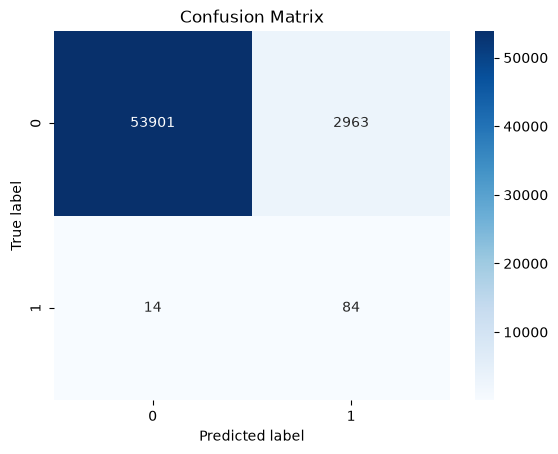

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     56864
           1       0.03      0.86      0.05        98

    accuracy                           0.95     56962
   macro avg       0.51      0.90      0.51     56962
weighted avg       1.00      0.95      0.97     56962



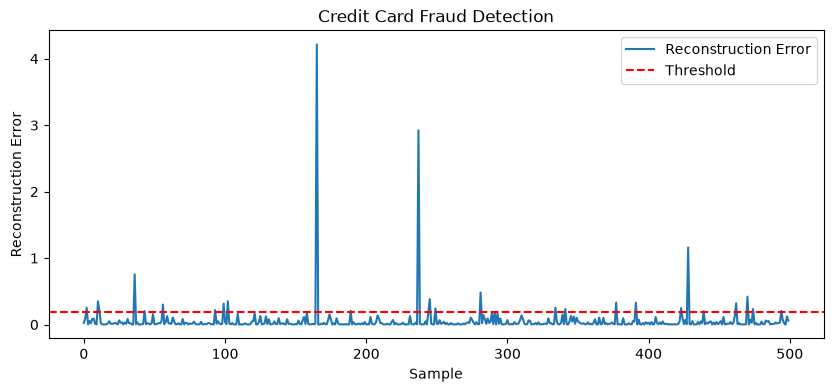

In [8]:
val_reconstruction = model.predict(X_val_normal)
val_errors = np.mean(np.square(X_val_normal - val_reconstruction), axis=1)

threshold = np.percentile(val_errors, 95)

test_reconstruction = model.predict(X_test)
test_errors = np.mean(np.square(X_test - test_reconstruction), axis=1)

predictions = (test_errors > threshold).astype(int)

print("Threshold:", threshold)
evaluate_anomalies(y_test, predictions)
plot_errors(test_errors[:500], threshold, 'Credit Card Fraud Detection')

# 3B. Industrial Equipment Anomaly Detection using MVTec AD

**Dataset:** MVTec Anomaly Detection (MVTec AD).

The model is trained on defect-free images from the `train/good` folder. Test images are stored in `test/good` and defect folders.

**Before running:** Set `DATASET_PATH` to the downloaded MVTec category folder, for example `.../bottle`. This example processes one category at a time.

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),

    # Encoder
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2), padding='same'),
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2), padding='same'),

    # Decoder
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.UpSampling2D((2, 2)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.UpSampling2D((2, 2)),
    tf.keras.layers.Conv2D(3, (3, 3), activation='sigmoid', padding='same')
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# 3C. Energy Consumption Anomaly Detection using LSTM Autoencoder

**Dataset:** Smart Grid / household energy consumption CSV.

This section expects a CSV with one numeric consumption column. Set `CSV_PATH` and `CONSUMPTION_COLUMN` to match the downloaded dataset. The example assumes the data is already ordered by timestamp. It trains on the first 80% of the readings as normal data.

## Stage 1: Load and preprocess data

In [18]:
CSV_PATH = 'dataset/AutoEncoder/EC/energy.csv'
WINDOW_SIZE = 24

data = pd.read_csv(CSV_PATH)

FEATURES = [
    'Electricity_Consumed',
    'Temperature',
    'Humidity',
    'Wind_Speed',
    'Avg_Past_Consumption'
]

values = data[FEATURES].values
labels = data['Anomaly_Label'].values

scaler = MinMaxScaler()
values = scaler.fit_transform(values)

train_values, test_values, train_labels, test_labels = train_test_split(
    values, labels,
    test_size=0.2,
    random_state=42
)


def create_windows(values, labels, window_size):
    windows = []
    window_labels = []

    for i in range(len(values) - window_size + 1):
        windows.append(values[i:i + window_size])
        window_labels.append(labels[i + window_size - 1])

    return np.array(windows), np.array(window_labels)


x_train, y_train = create_windows(
    train_values, train_labels, WINDOW_SIZE
)

x_test, y_test = create_windows(
    test_values, test_labels, WINDOW_SIZE
)

x_train_normal = x_train[y_train == 0]

print("Normal training windows:", x_train_normal.shape)
print("Testing windows:", x_test.shape)

Normal training windows: (3784, 24, 5)
Testing windows: (977, 24, 5)


## Stage 2: Define the LSTM autoencoder

In [19]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW_SIZE, 5)),
    # Encoder
    tf.keras.layers.LSTM(32, activation='tanh'),
    # Decoder
    tf.keras.layers.RepeatVector(WINDOW_SIZE),
    tf.keras.layers.LSTM(32, activation='tanh', return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(5))
])

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 24, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 5)          │           165 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

## Stage 3: Train the model

In [20]:
history = model.fit(
    x_train, x_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - loss: 0.0413 - val_loss: 0.0224
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0213 - val_loss: 0.0205
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0207 - val_loss: 0.0203
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0205 - val_loss: 0.0202
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0204 - val_loss: 0.0201
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0203 - val_loss: 0.0201
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0203 - val_loss: 0.0199
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0202 - val_loss: 0.0199
Epoch 9/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0201 - val_loss: 0.0198
Epoch 10/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0200 - val_loss: 0.0197


## Stage 4: Calculate reconstruction error and detect anomalies

119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Threshold: 0.0243493296477784
Detected anomalous windows: 68


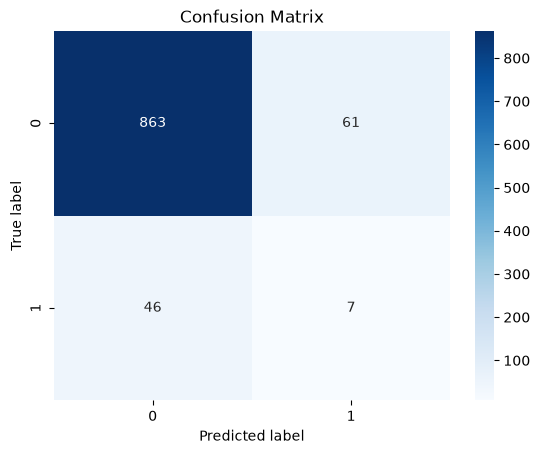

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94       924
           1       0.10      0.13      0.12        53

    accuracy                           0.89       977
   macro avg       0.53      0.53      0.53       977
weighted avg       0.90      0.89      0.90       977



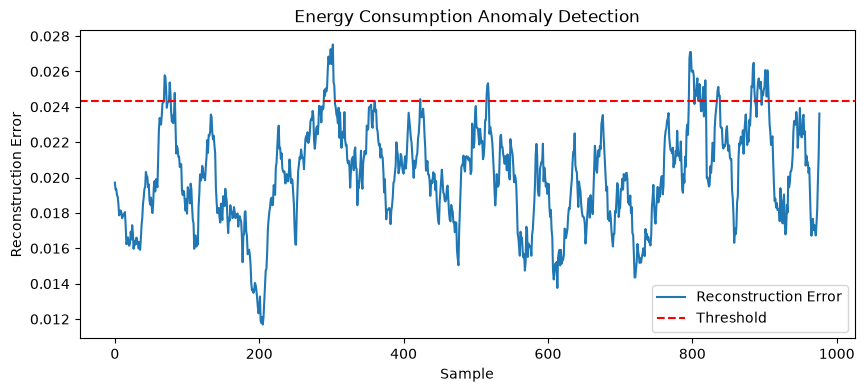

In [21]:
# Calculate threshold using normal training data
train_reconstruction = model.predict(x_train_normal)

train_errors = np.mean(
    np.square(x_train_normal - train_reconstruction),
    axis=(1, 2)
)

threshold = np.percentile(train_errors, 95)

# Evaluate on test data
test_reconstruction = model.predict(x_test)

test_errors = np.mean(
    np.square(x_test - test_reconstruction),
    axis=(1, 2)
)

predictions = (test_errors > threshold).astype(int)

print("Threshold:", threshold)
print("Detected anomalous windows:", np.sum(predictions))

evaluate_anomalies(y_test, predictions)

plot_errors(
    test_errors,
    threshold,
    'Energy Consumption Anomaly Detection'
)

# 3D. NASA Turbofan Engine Fault Detection using LSTM Autoencoder

**Dataset:** NASA C-MAPSS (`train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt`).

C-MAPSS does not provide a simple faulty/healthy label for every training row. This practical uses early cycles of each training engine as normal examples. Test windows are labelled as near-failure when the supplied remaining useful life (RUL) is 30 cycles or less. This is a simple practical approximation, not an official fault label.

## Stage 1: Load and preprocess sensor data

In [38]:
CSV_PATH = 'dataset/AutoEncoder/NASA/fan.csv'
WINDOW_SIZE = 20

data = pd.read_csv(CSV_PATH)

sensor_columns = [f'sensor{i}' for i in range(1, 22)]

In [39]:
def make_engine_windows(values, window_size):
    windows = []

    for i in range(len(values) - window_size + 1):
        windows.append(values[i:i + window_size])

    return windows

normal_data = data[data['Fault_Label'] == 0]

scaler = StandardScaler()
scaler.fit(normal_data[sensor_columns])

train_windows = []

for unit in normal_data['unit'].unique():
    values = scaler.transform(
        normal_data[normal_data['unit'] == unit][sensor_columns]
    )

    train_windows.extend(
        make_engine_windows(values, WINDOW_SIZE)
    )

x_train = np.array(train_windows)

print("Training windows:", x_train.shape)

Training windows: (15631, 20, 21)


In [40]:
test_windows = []
test_labels = []

for unit in data['unit'].unique():
    engine_data = data[data['unit'] == unit]

    values = scaler.transform(engine_data[sensor_columns])
    windows = make_engine_windows(values, WINDOW_SIZE)

    labels = engine_data['Fault_Label'].values[WINDOW_SIZE - 1:]

    test_windows.extend(windows)
    test_labels.extend(labels)

x_test = np.array(test_windows)
y_test = np.array(test_labels)

print("Testing windows:", x_test.shape)
print("Testing labels:", np.unique(y_test, return_counts=True))

Testing windows: (18731, 20, 21)
Testing labels: (array([0, 1]), array([15631,  3100]))


## Stage 2: Define the LSTM autoencoder

In [41]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW_SIZE, 21)),
    tf.keras.layers.LSTM(32, activation='tanh'),
    tf.keras.layers.RepeatVector(WINDOW_SIZE),
    tf.keras.layers.LSTM(32, activation='tanh', return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(21))
])

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 32)             │         6,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_3 (RepeatVector)  │ (None, 20, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 20, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_3              │ (None, 20, 21)         │           693 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,925 (62.21 KB)

 Trainable params: 15,925 (62.21 KB)

 Non-trainable params: 0 (0.00 B)

## Stage 3: Train the model on normal engine data

In [42]:
history = model.fit(
    x_train, x_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - loss: 0.3243 - val_loss: 0.2706
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2847 - val_loss: 0.2646
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2796 - val_loss: 0.2607
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2763 - val_loss: 0.2580
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2734 - val_loss: 0.2553
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2707 - val_loss: 0.2534
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2686 - val_loss: 0.2517
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2672 - val_loss: 0.2508
Epoch 9/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2659 - val_loss: 0.2492
Epoch 10/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2645 - val_loss: 0.2481


## Stage 4: Detect abnormal engine windows

489/489 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
Threshold: 0.4381556844324847


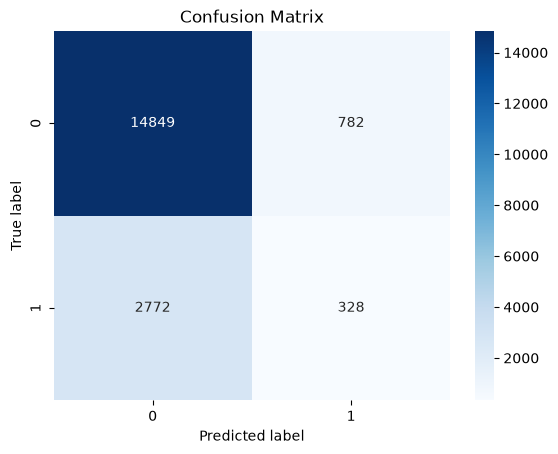

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89     15631
           1       0.30      0.11      0.16      3100

    accuracy                           0.81     18731
   macro avg       0.57      0.53      0.52     18731
weighted avg       0.75      0.81      0.77     18731



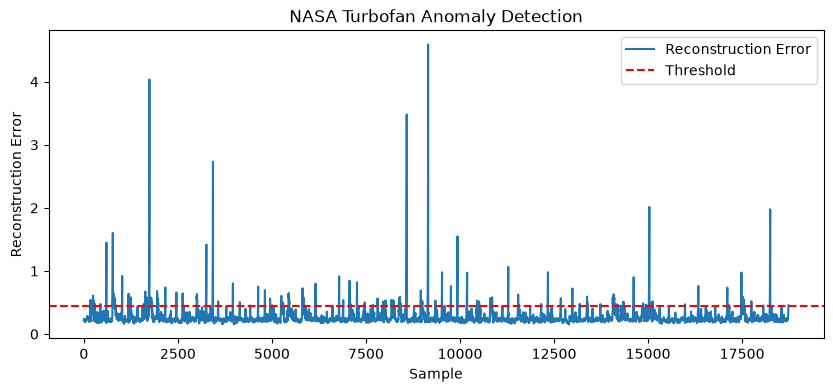

In [43]:
train_reconstruction = model.predict(x_train)
train_errors = np.mean(np.square(x_train - train_reconstruction), axis=(1, 2))
threshold = np.percentile(train_errors, 95)

test_reconstruction = model.predict(x_test)
test_errors = np.mean(np.square(x_test - test_reconstruction), axis=(1, 2))
predictions = (test_errors > threshold).astype(int)

print("Threshold:", threshold)
evaluate_anomalies(y_test, predictions)
plot_errors(test_errors, threshold, 'NASA Turbofan Anomaly Detection')

# 3F. Sign Language MNIST – Detect alphabet Y as an anomaly

**Normal classes:** The other 23 alphabet classes.

**Anomaly class:** Y (label 24).

The model is trained only on images from the other 23 classes. Images labelled Y are treated as anomalies.

## Stage 1: Load and preprocess data

In [9]:
train_data = pd.read_csv('dataset/fnn_cnn/sign/sign_mnist_train.csv')
test_data = pd.read_csv('dataset/fnn_cnn/sign/sign_mnist_test.csv')

x_train = train_data.drop('label', axis=1).to_numpy()
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).to_numpy()
y_test = test_data['label'].values

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [10]:
# Keep all classes except Y (label 24) for training.
normal_train = x_train[y_train != 24]

# Test data includes normal classes and the Y anomaly class.
y_test_anomaly = (y_test == 24).astype(int)

print("Normal training images:", normal_train.shape)
print("Test images:", x_test.shape)
print("Anomaly images in test set:", np.sum(y_test_anomaly))

Normal training images: (26337, 28, 28, 1)
Test images: (7172, 28, 28, 1)
Anomaly images in test set: 332


## Stage 2: Define the autoencoder

In [11]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Encoder
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2), padding='same'),
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2), padding='same'),

    # Decoder
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.UpSampling2D((2, 2)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.UpSampling2D((2, 2)),
    tf.keras.layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')
])

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

## Stage 3: Train on the 23 normal classes

In [12]:
normal_train, normal_val = train_test_split(
    normal_train, test_size=0.2, random_state=42
)

history = model.fit(
    normal_train, normal_train,
    epochs=10,
    batch_size=128,
    validation_data=(normal_val, normal_val)
)

Epoch 1/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - loss: 0.0156 - val_loss: 0.0072
Epoch 2/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - loss: 0.0059 - val_loss: 0.0051
Epoch 3/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - loss: 0.0048 - val_loss: 0.0044
Epoch 4/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 102ms/step - loss: 0.0043 - val_loss: 0.0041
Epoch 5/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - loss: 0.0040 - val_loss: 0.0039
Epoch 6/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - loss: 0.0038 - val_loss: 0.0038
Epoch 7/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - loss: 0.0037 - val_loss: 0.0035
Epoch 8/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - loss: 0.0035 - val_loss: 0.0034
Epoch 9/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - loss: 0.0034 - val_loss: 0.0034
Epoch 10/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - loss: 0.0033 - val_loss: 0.0032


## Stage 4: Detect Y as an anomaly

165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step
Threshold: 0.006054471


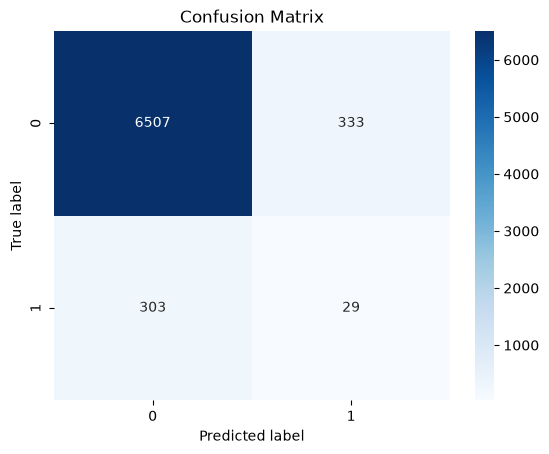

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.95      0.95      6840
           1       0.08      0.09      0.08       332

    accuracy                           0.91      7172
   macro avg       0.52      0.52      0.52      7172
weighted avg       0.91      0.91      0.91      7172



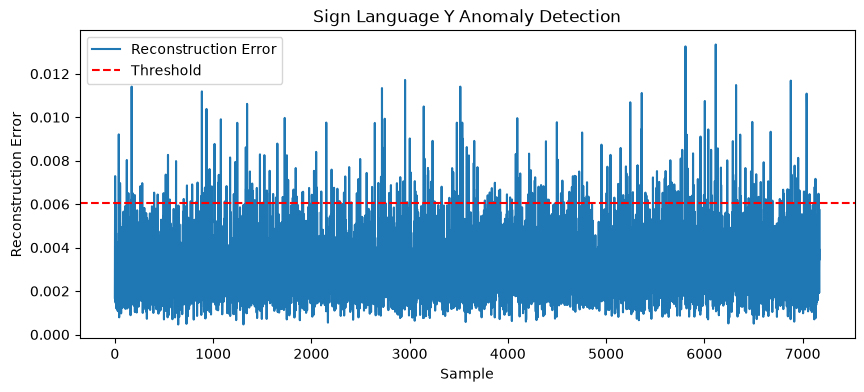

In [17]:
val_reconstruction = model.predict(normal_val)
val_errors = np.mean(
    np.square(normal_val - val_reconstruction), axis=(1, 2)
)
threshold = np.percentile(val_errors, 95)

test_reconstruction = model.predict(x_test)
test_errors = np.mean(
    np.square(x_test - test_reconstruction), axis=(1, 2)
)

predictions = (test_errors > threshold).astype(int)

print("Threshold:", threshold)
evaluate_anomalies(y_test_anomaly, predictions)
plot_errors(test_errors, threshold, "Sign Language Y Anomaly Detection")

# ECG LOADING

In [49]:
data = pd.read_csv('dataset/AutoEncoder/ECG/ecg.csv', header=None)

X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_normal = X_train[y_train == 1]

X_train_normal, X_val_normal = train_test_split(
    X_train_normal, test_size=0.2, random_state=42
)

print("Normal training transactions:", X_train_normal.shape)
print("Test transactions:", X_test.shape)

Normal training transactions: (1868, 140)
Test transactions: (1000, 140)


In [50]:
input_dim = X_train_normal.shape[1]

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(input_dim,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(input_dim, activation='linear')
])

model.compile(
    optimizer='adam',
    loss='mse'
)

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 32)             │         4,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 140)            │         4,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,204 (39.86 KB)

 Trainable params: 10,204 (39.86 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
history = model.fit(
    X_train_normal, X_train_normal,
    epochs=20,
    batch_size=256,
    validation_data=(X_val_normal, X_val_normal)
)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.7841 - val_loss: 0.8144
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.7330 - val_loss: 0.7547
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6671 - val_loss: 0.6758
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5874 - val_loss: 0.5908
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5092 - val_loss: 0.5137
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4434 - val_loss: 0.4524
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3935 - val_loss: 0.4041
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.3521 - val_loss: 0.3636
Epoch 9/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3167 - val_loss: 0.3278
Epoch 10/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2863 - val_loss: 0.2956
Epoch 11/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2582 - val_loss: 0.2683
Epoch 12/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2352 - val_loss: 0.2468
E

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Threshold: 0.4387905765521059


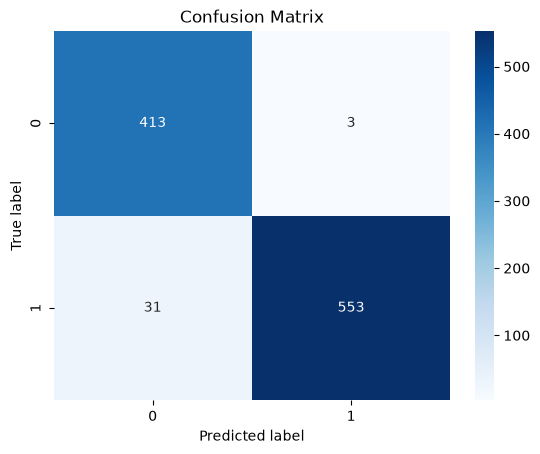

Classification Report:
              precision    recall  f1-score   support

         0.0       0.93      0.99      0.96       416
         1.0       0.99      0.95      0.97       584

    accuracy                           0.97      1000
   macro avg       0.96      0.97      0.97      1000
weighted avg       0.97      0.97      0.97      1000



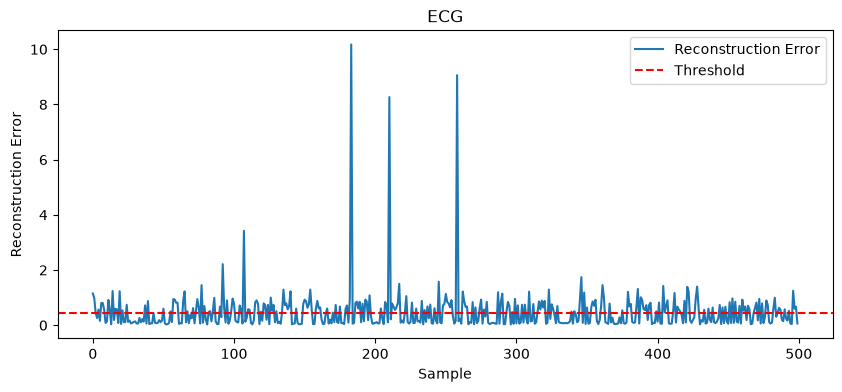

In [56]:
val_reconstruction = model.predict(X_val_normal)
val_errors = np.mean(np.square(X_val_normal - val_reconstruction), axis=1)

threshold = np.percentile(val_errors, 95)

test_reconstruction = model.predict(X_test)
test_errors = np.mean(np.square(X_test - test_reconstruction), axis=1)

predictions = (test_errors > threshold).astype(int)
predictions = 1 - predictions

print("Threshold:", threshold)
evaluate_anomalies(y_test, predictions)
plot_errors(test_errors[:500], threshold, 'ECG')